# 05 — Model Intuition

This notebook is about *understanding* the trained model — not measuring it. We trace individual predictions step-by-step, inspect the decision surface, probe which features matter, and find the samples the model finds hardest.

**Run all cells top-to-bottom.** Notebook 04 must have run first (it writes `artifacts/final_model.pt`).

> **Kernel:** `source /root/LLM/venv/bin/activate && jupyter notebook`

**What we do:** Import libraries, load the final model checkpoint from disk, and reconstruct the standardised test set.
**Why:** Everything in this notebook flows from the saved checkpoint — no in-memory state from earlier runs.
**What you should see:** Model architecture and device.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import json

from tools.nets.mlp import MLP
from tools.observability.hooks import register_activation_hooks
from tools.viz.activations import (plot_activation_landscape,
                                   plot_layer_representations,
                                   plot_neuron_weights)

FORCE_CPU = False
SEED      = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

NOTEBOOK_DIR  = pathlib.Path().resolve()
ARTIFACTS_DIR = NOTEBOOK_DIR.parent / "artifacts"

env  = json.loads((ARTIFACTS_DIR / "env.json").read_text())
ckpt = torch.load(ARTIFACTS_DIR / "final_model.pt",
                  map_location="cpu", weights_only=False)

device = torch.device("cpu" if FORCE_CPU else env.get("device", "cpu"))
model  = MLP(ckpt["layer_sizes"]).to(device)
model.load_state_dict(ckpt["model_state"])
model.eval()

# pool scaler (fitted on all 800 non-test rows in notebook 04)
mu_f  = np.array(ckpt["scaler"]["mean"])
sig_f = np.array(ckpt["scaler"]["std"])

# test set
test_data  = np.load(ARTIFACTS_DIR / "test_set.npz")
X_test_raw = test_data["X"]
y_test     = test_data["y"]
X_test     = (X_test_raw - mu_f) / sig_f

X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)

print(model)
print(f"\ndevice : {device}")
print(f"test   : {X_test.shape}")

MLP(
  (layers): ModuleList(
    (0): Linear(in_features=3, out_features=3, bias=True)
    (1): Linear(in_features=3, out_features=2, bias=True)
    (2): Linear(in_features=2, out_features=1, bias=True)
  )
  (acts): ModuleList(
    (0-1): 2 x Tanh()
    (2): Sigmoid()
  )
)

device : cuda
test   : (200, 3)


**What we do:** Trace one *correctly* classified sample through every layer, printing the pre-activation `a(l)` and post-activation `z(l)` values.
**Why:** This is the forward pass written out in human-readable form — exactly what the network computes for a single input.
**What you should see:** Vectors shrinking to a scalar at the output, with the final sigmoid producing P(class=1).

In [2]:
def forward_trace(model, x_std, true_label, device):
    z = torch.tensor(x_std[None], dtype=torch.float32).to(device)
    print(f"  z(0) — input       : {z.flatten().tolist()}")
    for l, (linear, act) in enumerate(zip(model.layers, model.acts)):
        a = linear(z)
        z = act(a)
        act_name = type(act).__name__
        print(f"  a({l+1}) — pre-act L{l+1} : {[round(v, 4) for v in a.flatten().tolist()]}")
        print(f"  z({l+1}) — {act_name:8s} L{l+1}: {[round(v, 4) for v in z.flatten().tolist()]}")
    prob = z.item()
    pred = int(prob > 0.5)
    result = "✓ correct" if pred == int(true_label) else "✗ wrong"
    print(f"\n  P(class=1) = {prob:.4f}  → pred={pred}  true={int(true_label)}  {result}")
    return prob

model.eval()
with torch.no_grad():
    probs_all = model(X_test_t).squeeze().cpu().numpy()

correct_mask = ((probs_all > 0.5) == y_test.astype(bool))
confident    = np.argsort(np.abs(probs_all - 0.5))[::-1]
pick_idx     = next(i for i in confident if correct_mask[i])

print(f"=== Correct prediction (sample #{pick_idx}) ===")
print(f"Raw input (x1, x2, x3) = {X_test_raw[pick_idx].tolist()}")
print(f"Standardised input      = {[round(v,4) for v in X_test[pick_idx].tolist()]}")
print()
_ = forward_trace(model, X_test[pick_idx], y_test[pick_idx], device)

=== Correct prediction (sample #159) ===
Raw input (x1, x2, x3) = [1.138344645500183, -0.2505214214324951, 1.6704555749893188]
Standardised input      = [1.0881, -0.2524, 1.6907]

  z(0) — input       : [1.088120460510254, -0.252391517162323, 1.6906598806381226]
  a(1) — pre-act L1 : [-2.0463, 0.6609, 1.2177]
  z(1) — Tanh     L1: [-0.9672, 0.579, 0.839]
  a(2) — pre-act L2 : [-3.1974, 3.5221]
  z(2) — Tanh     L2: [-0.9967, 0.9983]
  a(3) — pre-act L3 : [4.8115]
  z(3) — Sigmoid  L3: [0.9919]

  P(class=1) = 0.9919  → pred=1  true=1  ✓ correct


**What we do:** Repeat the trace for one *wrong* prediction.
**Why:** Seeing where the network commits a confident error reveals the limits of what it learned — usually a point where the input features are ambiguous or the decision boundary passes very close.
**What you should see:** The final probability on the wrong side of 0.5, with annotated correct label.

In [3]:
wrong_mask = ~correct_mask
if wrong_mask.any():
    wrong_confident = next(i for i in confident if wrong_mask[i])
    print(f"=== Wrong prediction (sample #{wrong_confident}) ===")
    print(f"Raw input (x1, x2, x3) = {X_test_raw[wrong_confident].tolist()}")
    print(f"Standardised input      = {[round(v,4) for v in X_test[wrong_confident].tolist()]}")
    print()
    _ = forward_trace(model, X_test[wrong_confident], y_test[wrong_confident], device)
else:
    print("No wrong predictions on the test set — perfect accuracy!")

=== Wrong prediction (sample #122) ===
Raw input (x1, x2, x3) = [0.7199674844741821, 0.41140761971473694, 1.931160569190979]
Standardised input      = [0.6796, 0.394, 1.9574]

  z(0) — input       : [0.6796426177024841, 0.39404022693634033, 1.9573891162872314]
  a(1) — pre-act L1 : [-1.4178, 0.0466, 2.5628]
  z(1) — Tanh     L1: [-0.8891, 0.0466, 0.9882]
  a(2) — pre-act L2 : [-2.491, 2.237]
  z(2) — Tanh     L2: [-0.9864, 0.9775]
  a(3) — pre-act L3 : [4.7473]
  z(3) — Sigmoid  L3: [0.9914]

  P(class=1) = 0.9914  → pred=1  true=0  ✗ wrong


**What we do:** Plot the model's decision surface in the (x₁, x₂) plane with x₃ fixed at 0 (the feature mean after standardisation). Test-set points are overlaid, coloured by true class, with wrong predictions marked with an × instead of a dot.
**Why:** A 2D slice of the decision boundary shows the shape of what the network learned — whether it separates classes with a line, a curve, or a more complex region.
**What you should see:** A blue-red background with a curved boundary; correctly classified points cluster on the matching colour side.

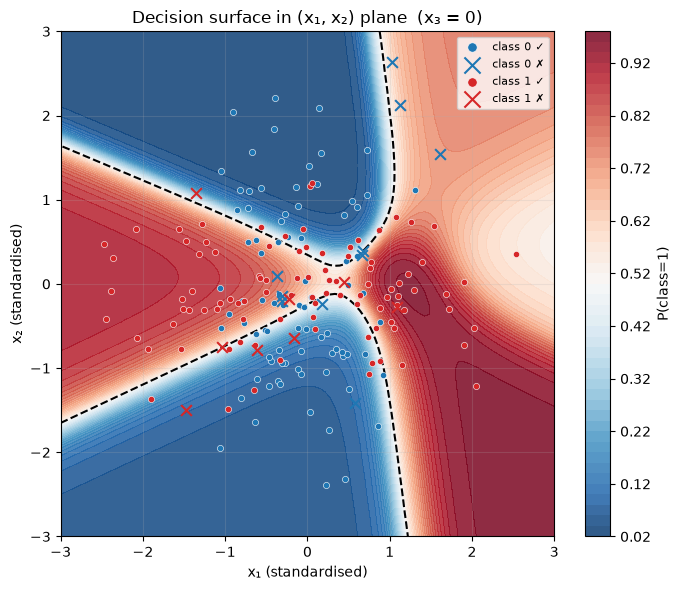

In [4]:
N_GRID = 100
xs = np.linspace(-3, 3, N_GRID)
ys = np.linspace(-3, 3, N_GRID)
XX, YY = np.meshgrid(xs, ys)
grid_std = np.stack([XX.ravel(), YY.ravel(),
                     np.zeros(N_GRID * N_GRID)], axis=1).astype(np.float32)

with torch.no_grad():
    ZZ = model(torch.tensor(grid_std).to(device)).cpu().numpy().reshape(N_GRID, N_GRID)

fig, ax = plt.subplots(figsize=(7, 6))
cf = ax.contourf(XX, YY, ZZ, levels=50, cmap="RdBu_r", vmin=0, vmax=1, alpha=0.85)
ax.contour(XX, YY, ZZ, levels=[0.5], colors="k", linewidths=1.5, linestyles="--")
plt.colorbar(cf, ax=ax, label="P(class=1)")

preds_test = (probs_all > 0.5).astype(int)
correct    = preds_test == y_test.astype(int)

for cls, color in [(0, "C0"), (1, "C3")]:
    mask_ok  = (y_test == cls) & correct
    mask_bad = (y_test == cls) & ~correct
    ax.scatter(X_test[mask_ok,  0], X_test[mask_ok,  1], c=color, s=20,
               edgecolors="white", linewidths=0.4, label=f"class {cls} ✓", zorder=3)
    ax.scatter(X_test[mask_bad, 0], X_test[mask_bad, 1], c=color, s=60,
               marker="x", linewidths=1.5, label=f"class {cls} ✗", zorder=4)

ax.set_xlabel("x₁ (standardised)"); ax.set_ylabel("x₂ (standardised)")
ax.set_title("Decision surface in (x₁, x₂) plane  (x₃ = 0)")
ax.legend(markerscale=1.5, fontsize=8); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "decision_surface.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Partial-dependence plots — sweep each input feature independently from −3 to +3 (standardised) while holding the other two at 0, and plot how P(class=1) responds.
**Why:** This shows the model's marginal sensitivity to each feature in isolation. The true boundary is `x1²−x2²+x3>0`, so we expect a non-linear response to x₁ and x₂ but a roughly monotone one to x₃.
**What you should see:** Non-linear U-shaped or inverted-U curves for x₁ and x₂; a roughly sigmoid-shaped curve for x₃.

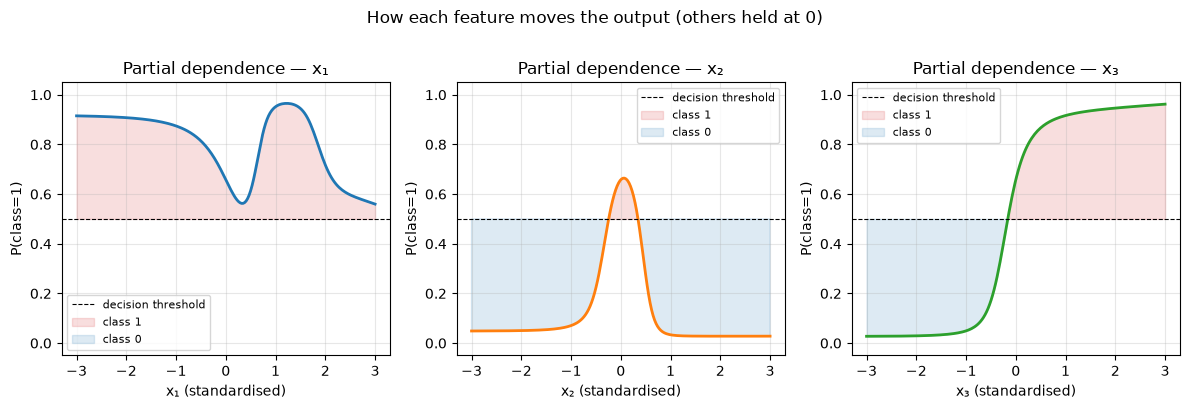

In [5]:
sweep = np.linspace(-3, 3, 200)
zero  = np.zeros(200)
feature_names = ["x₁", "x₂", "x₃"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for k, (ax, name) in enumerate(zip(axes, feature_names)):
    inputs = np.zeros((200, 3), dtype=np.float32)
    inputs[:, k] = sweep
    with torch.no_grad():
        preds_pd = model(torch.tensor(inputs).to(device)).cpu().numpy().squeeze()
    ax.plot(sweep, preds_pd, lw=2, color=f"C{k}")
    ax.axhline(0.5, color="k", linestyle="--", lw=0.8, label="decision threshold")
    ax.fill_between(sweep, 0.5, preds_pd, where=preds_pd >= 0.5,
                    alpha=0.15, color="C3", label="class 1")
    ax.fill_between(sweep, preds_pd, 0.5, where=preds_pd < 0.5,
                    alpha=0.15, color="C0", label="class 0")
    ax.set_xlabel(f"{name} (standardised)"); ax.set_ylabel("P(class=1)")
    ax.set_title(f"Partial dependence — {name}")
    ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("How each feature moves the output (others held at 0)", y=1.01)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "partial_dependence.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Compute the gradient of the output with respect to each input feature for every test sample — `dP/dx` — and plot the mean absolute gradient per feature.
**Why:** The gradient tells you how much the model's prediction would change if you nudged each feature slightly. High gradient → that feature is driving the decision at this point in input space.
**What you should see:** x₁ and x₂ should show higher sensitivity than x₃ on average, reflecting the `x1²−x2²` dominant term in the true boundary.

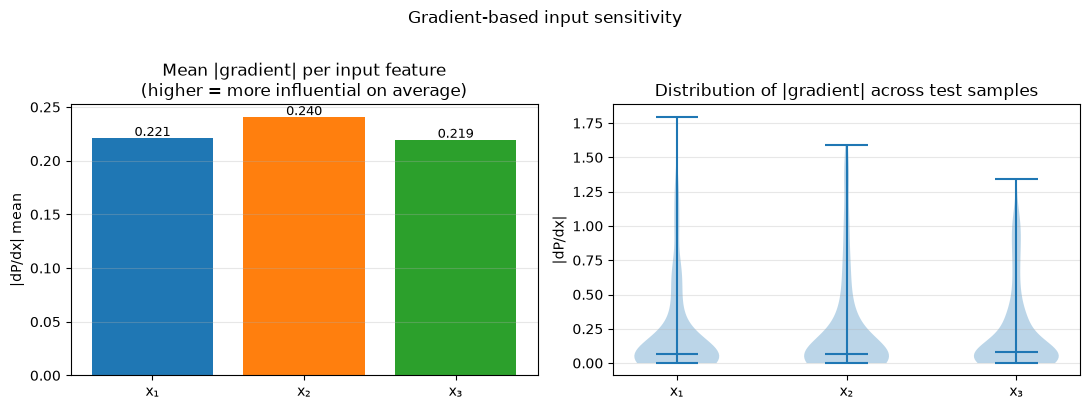

Mean |gradient| per feature:
  x₁: 0.2211
  x₂: 0.2405
  x₃: 0.2193


In [6]:
X_grad = X_test_t.clone().detach().requires_grad_(True)
out    = model(X_grad)
out.sum().backward()

grads    = X_grad.grad.cpu().numpy()
abs_grad = np.abs(grads)
mean_abs = abs_grad.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.bar(feature_names, mean_abs, color=["C0","C1","C2"])
ax.set_ylabel("|dP/dx| mean")
ax.set_title("Mean |gradient| per input feature\n(higher = more influential on average)")
ax.grid(axis="y", alpha=0.3)
for i, v in enumerate(mean_abs):
    ax.text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)

ax2 = axes[1]
ax2.violinplot([abs_grad[:, k] for k in range(3)],
               positions=[0, 1, 2], showmedians=True)
ax2.set_xticks([0, 1, 2]); ax2.set_xticklabels(feature_names)
ax2.set_ylabel("|dP/dx|")
ax2.set_title("Distribution of |gradient| across test samples")
ax2.grid(axis="y", alpha=0.3)

fig.suptitle("Gradient-based input sensitivity", y=1.01)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "gradient_sensitivity.png", dpi=100, bbox_inches="tight")
plt.show()

print("Mean |gradient| per feature:")
for name, g in zip(feature_names, mean_abs):
    print(f"  {name}: {g:.4f}")

**What we do:** Find the test samples where the model is least certain — P(class=1) closest to 0.5 — and print their raw feature values alongside the probability and true label.
**Why:** Near-boundary samples reveal *where* the decision surface sits in real-valued feature space. If these points look genuinely ambiguous, the model is well-calibrated; if they look clearly one class, something went wrong.
**What you should see:** 10 rows with probability between ~0.4 and ~0.6, with the true label shown so you can judge whether the uncertainty is warranted.

In [7]:
uncertainty = np.abs(probs_all - 0.5)
near_idx    = np.argsort(uncertainty)[:10]    # 10 most uncertain

print(f"{'idx':>5}  {'x1':>7}  {'x2':>7}  {'x3':>7}  {'P(1)':>7}  {'true':>5}  {'correct':>8}")
print("-" * 60)
for i in near_idx:
    x1, x2, x3 = X_test_raw[i]
    p    = probs_all[i]
    true = int(y_test[i])
    pred = int(p > 0.5)
    flag = "yes" if pred == true else "NO"
    print(f"{i:>5}  {x1:>7.3f}  {x2:>7.3f}  {x3:>7.3f}  {p:>7.4f}  {true:>5}  {flag:>8}")

  idx       x1       x2       x3     P(1)   true   correct
------------------------------------------------------------
   79    1.104   -0.522   -0.740   0.5039      1       yes
  127   -0.289   -0.205   -0.195   0.5068      0        NO
  176    0.834   -0.959    0.454   0.5133      1       yes
  160   -0.141   -0.646    0.410   0.4821      1        NO
  194    1.357    1.148   -0.858   0.4717      0       yes
  193   -1.646   -0.483   -0.740   0.5478      1       yes
   64   -0.500   -0.550    0.024   0.4483      0       yes
    5    0.772   -0.636    0.252   0.5587      1       yes
   44   -1.041   -0.765   -0.055   0.4274      1        NO
   27    1.071    2.712   -0.194   0.5752      0        NO


**What we do:** Check how saturated the tanh neurons are across the test set. A neuron is 'saturated' when |z(l)| > 0.9 — the tanh output is near ±1 and its gradient is near zero.
**Why:** Saturated neurons pass very little gradient during backpropagation. A high saturation fraction means the network may be near a local optimum where those neurons are effectively dead for further training.
**What you should see:** Saturation fraction per neuron; a histogram of activation values for each hidden layer.

Saturation analysis (|z| > 0.9 counted as saturated):

  Layer 1:
    Neuron 1: 54.5% saturated  (mean |z| = 0.802)
    Neuron 2: 68.0% saturated  (mean |z| = 0.832)
    Neuron 3: 34.0% saturated  (mean |z| = 0.700)
  Layer 2:
    Neuron 1: 39.0% saturated  (mean |z| = 0.747)
    Neuron 2: 23.5% saturated  (mean |z| = 0.539)


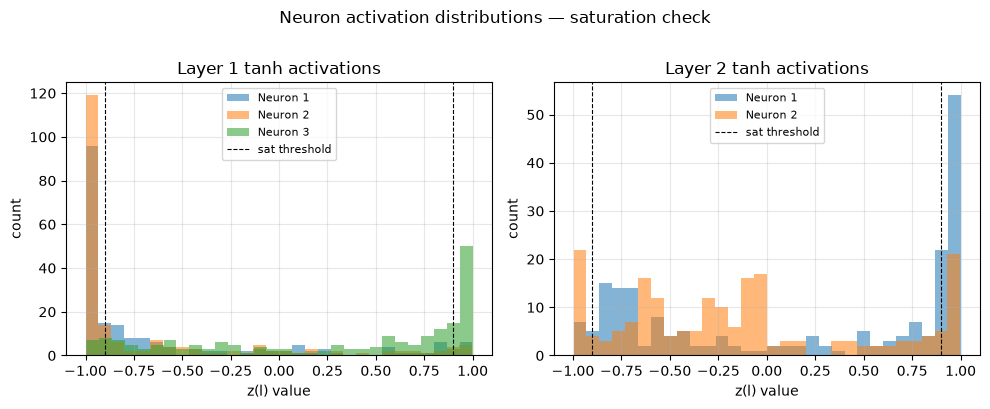

In [8]:
store, handles = register_activation_hooks(model)
with torch.no_grad():
    model(X_test_t)
for h in handles:
    h.remove()

n_hidden = len(model.layers) - 1    # tanh layers only
fig, axes = plt.subplots(1, n_hidden, figsize=(5 * n_hidden, 4))
if n_hidden == 1:
    axes = [axes]

print("Saturation analysis (|z| > 0.9 counted as saturated):")
print()
for l in range(n_hidden):
    Z = store[l].numpy()            # (N, n_neurons)
    sat_frac = (np.abs(Z) > 0.9).mean(axis=0)
    print(f"  Layer {l+1}:")
    for k, sf in enumerate(sat_frac):
        print(f"    Neuron {k+1}: {sf*100:.1f}% saturated  "
              f"(mean |z| = {np.abs(Z[:,k]).mean():.3f})")

    ax = axes[l]
    for k in range(Z.shape[1]):
        ax.hist(Z[:, k], bins=30, alpha=0.55, label=f"Neuron {k+1}")
    ax.axvline( 0.9, color="k", lw=0.8, linestyle="--", label="sat threshold")
    ax.axvline(-0.9, color="k", lw=0.8, linestyle="--")
    ax.set_title(f"Layer {l+1} tanh activations")
    ax.set_xlabel("z(l) value"); ax.set_ylabel("count")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

fig.suptitle("Neuron activation distributions — saturation check", y=1.01)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "saturation.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Plot the L1 neuron weight bars using the shared tool.
**Why:** Weight magnitudes show what each first-layer neuron amplifies or suppresses — the closest analogue to 'receptive fields' for tabular inputs.
**What you should see:** 3 bars per neuron subplot; the dominant feature alignment with the true boundary `x1²−x2²+x3>0` should be visible.

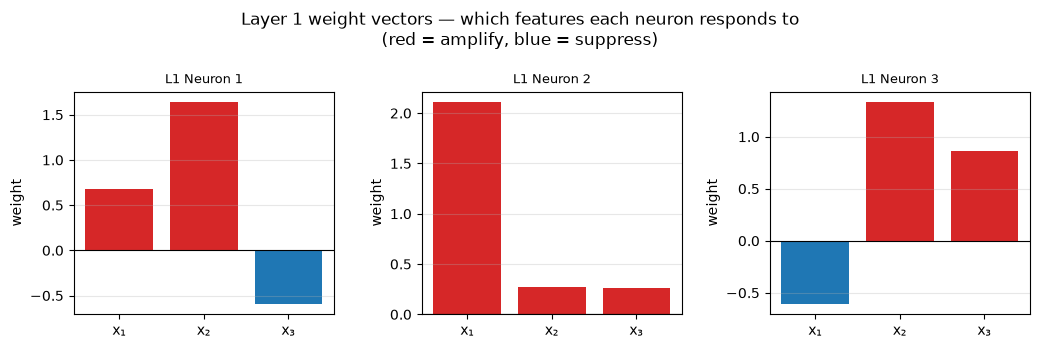

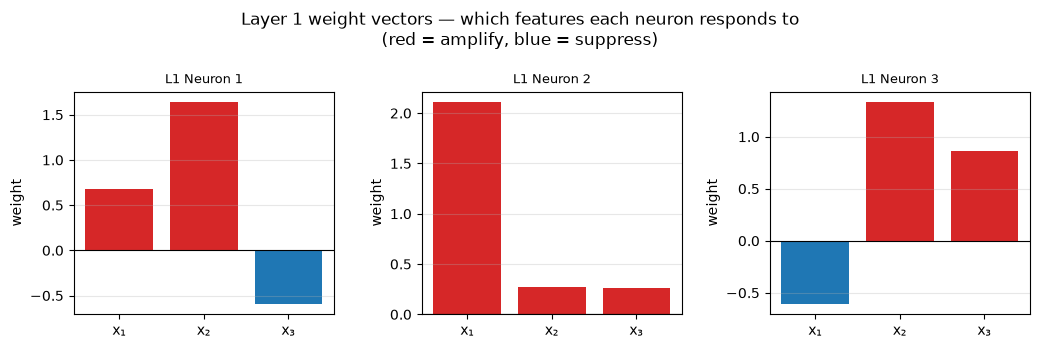

In [9]:
plot_neuron_weights(
    model,
    save_path=ARTIFACTS_DIR / "intuition_weights.png",
    feature_names=feature_names,
)

**What we do:** Sweep a 60×60 grid in (x₁, x₂) with x₃=0 and show each neuron's tanh activation as a filled contour map.
**Why:** Layer 1 neurons carve the input space into half-planes; layer 2 neurons combine these into curved regions. Comparing the two layers shows how abstraction grows from layer to layer.
**What you should see:** Simple linear boundaries in layer 1; more complex non-linear patterns in layer 2.

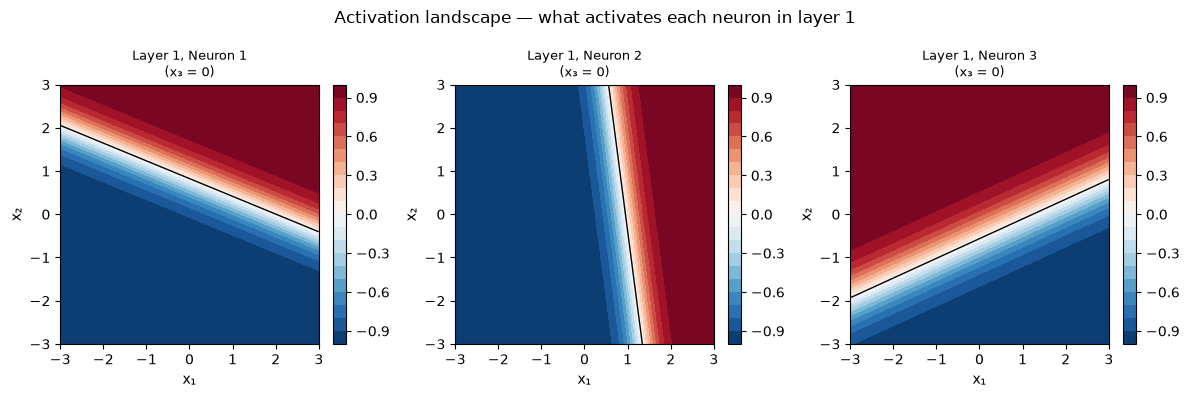

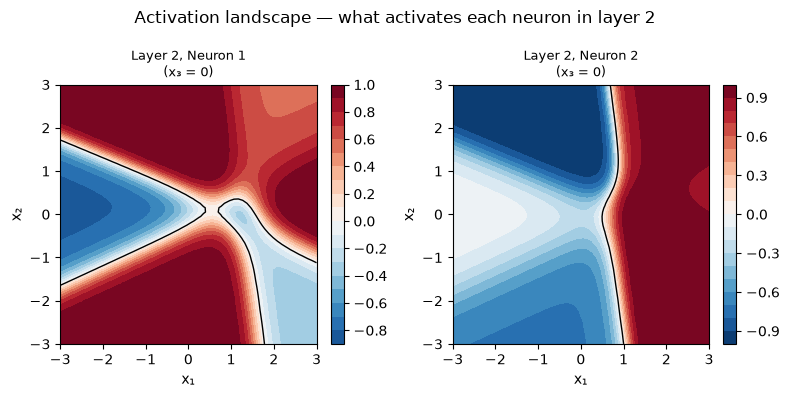

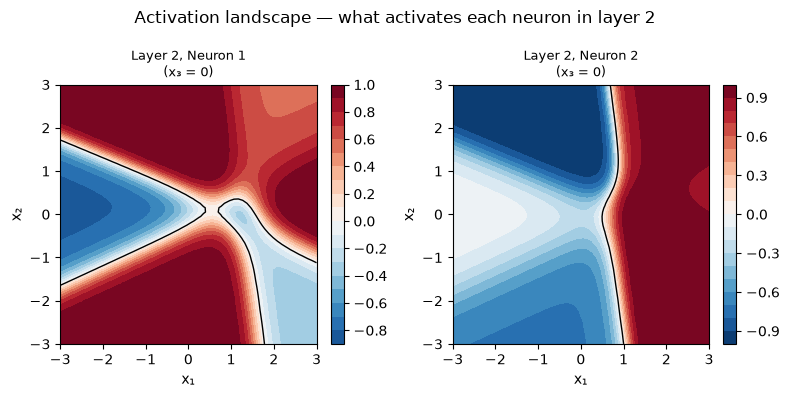

In [10]:
plot_activation_landscape(model, device, layer_idx=0,
                          save_path=ARTIFACTS_DIR / "intuition_landscape_L1.png")
plot_activation_landscape(model, device, layer_idx=1,
                          save_path=ARTIFACTS_DIR / "intuition_landscape_L2.png")

**What we do:** Scatter the test-set points in each layer's output space, coloured by true class.
**Why:** This shows how the network progressively 'untangles' the classes: in the raw feature space they overlap; by the output layer a simple threshold separates them.
**What you should see:** Interleaved clouds in the input panel; a progressively cleaner split in later panels.

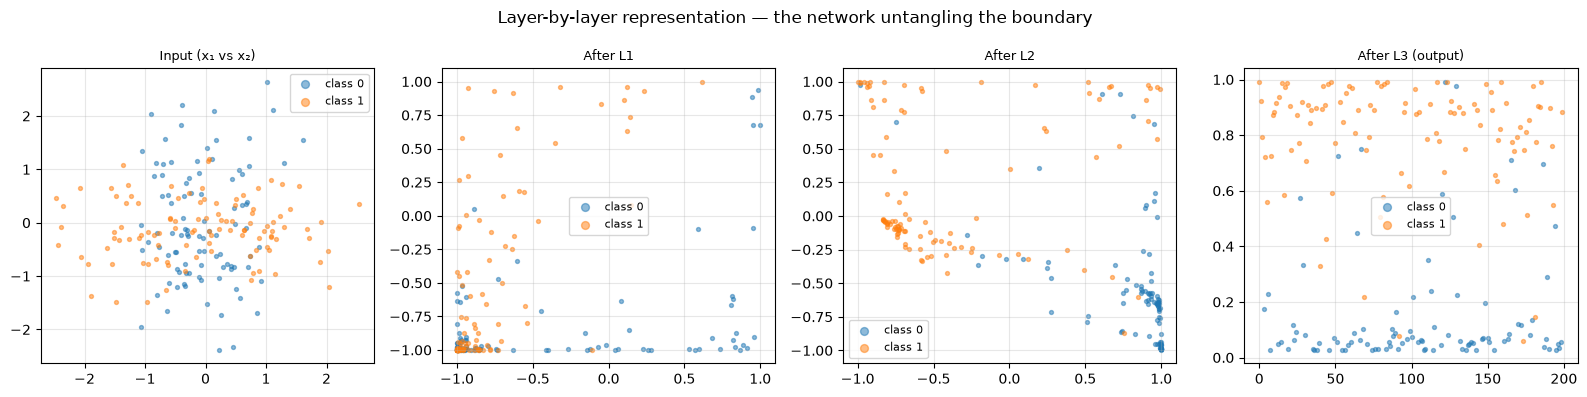

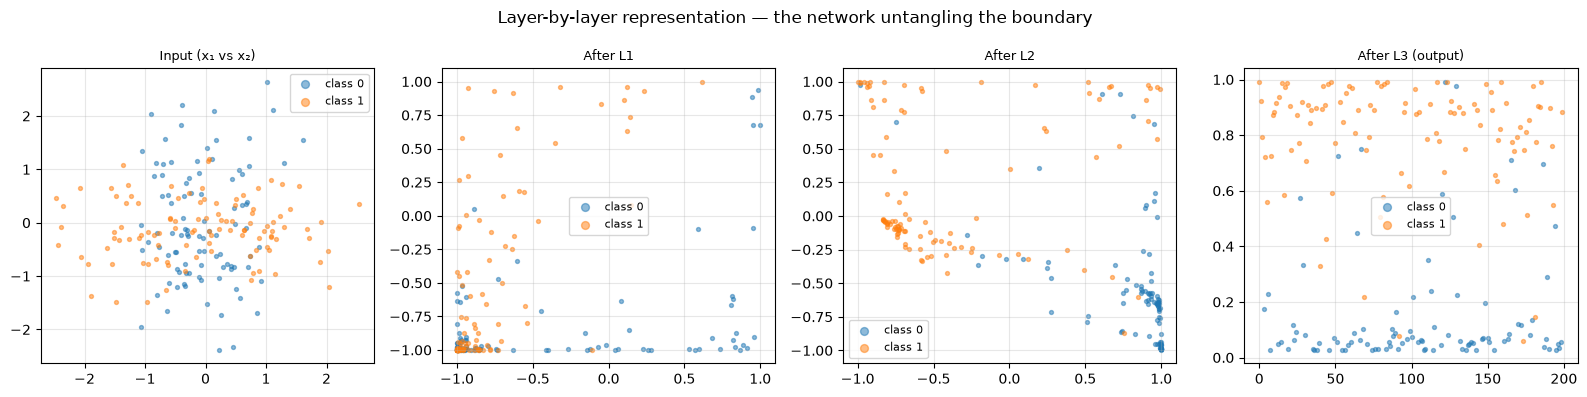

In [11]:
plot_layer_representations(
    model,
    X_test.astype(np.float32),
    y_test.astype(int),
    device,
    save_path=ARTIFACTS_DIR / "intuition_layer_representations.png",
)